## Обратное демографическое моделирование и анализ жилищного фонда г. Твери (2010–2021)

**Объект исследования:** Многоквартирный жилой фонд в административных границах города Твери.

**Цель:** Вычислить локальный измененный коэффициент среднего размера городского домохозяйства для г.Тверь на основе сопоставления емкости реестров ЖКХ и данных переписей населения 2010-го и 2021-го года, а также локализовать искажения данных через анализ этажности застройки.

*Данное исследование выполняется в рамках моей курсовой работы, посвященной электротранспорту города Тверь. 
 Полученные данные составят лишь малую часть общего исследования*

## Установка и импорт библиотек для работы

In [27]:
# Импортируем необходимые библиотеки
import os
import matplotlib.pyplot as plt
import pandas as pd

# Настраиваем шрифт графика, а также разрешение (DPI) для четкого отображения
plt.rcParams["font.family"] = "sans-serif" #настройка шрифта
plt.rcParams["figure.dpi"] = 150 #настройка разрешения



## Загрузка датасета и очистка данных
Загружаем массив данных Реформы ЖКХ "Реестр домов по Тверской области". Выделяем из общего массива Тверской области только город Тверь. Конвертируем данные в числа и очищаем датасет от текстовых ошибок: исключаем записи с нулевым количеством жилых помещений.



In [34]:
data_path = "data/reforma_jkh_tver.csv"

# Загружаем csv-файл в Pandas, указываем разделитель точку с запятой (sep=";")
# Параметр low_memory=False запрещает Pandas экономить память
df_raw = pd.read_csv(data_path, sep=";", low_memory=False)

# Фильтр таблицы: оставляем только те строки, где в колонке города написано "Тверь"
#.copy() создает копию таблицы в оперативной памяти компьютера
df_tver = df_raw[df_raw["formalname_city"] == "Тверь"].copy()

# Конвертируем колонку количества квартир в числа. errors="coerce" превращает текстовые ошибки в пустоту(NaN)
df_tver["living_quarters_count"] = pd.to_numeric(df_tver["living_quarters_count"], errors="coerce")

# Конвертируем колонку года постройки в числа также, как и колонку количества квартир
df_tver["built_year"] = pd.to_numeric(df_tver["built_year"], errors="coerce")

# Конвертируем колонку максимальной этажности в числовой формат для последующего анализа застройки
df_tver["floor_count_max"] = pd.to_numeric(df_tver["floor_count_max"], errors="coerce")

# Очищаем таблицу: оставляем дома, где количество квартир > 0
# На всякий случай проверяем год постройки на адекватность (здания, старше 1800-го года в любом случае не стоят на учете в ЖКХ и не являются многоквартирными домами, то есть объектом нашего исследования) 
df_tver = df_tver[(df_tver["living_quarters_count"] > 0) & (df_tver["built_year"] > 1800)]

# Вывод на экран итогового количества строк (домов), успешно прошедших очистку
print(f"После очистки данных в выборке по г.Тверь осталось {len(df_tver)} многоквартирных домов.")



После очистки данных в выборке по г.Тверь осталось 2208 многоквартирных домов.


## Расчет измененного коэффициента размера домохозяйства
Сопоставляем полученное после обработки число квартир из базы ЖКХ с официальными данными численности населения г.Тверь за 2010-й и 2021-й год. Поделив численность населения на физическое число квартир, мы выведем локальный измененный размер домохозяйства для Твери и попутно оценим степень полноты базы ЖКХ.


In [35]:
# Задаем константу официальной численности населения Твери на 2010 и 2021 год (данные росстата)
pop_2010 = 403606
pop_2021 = 416219

# Делаем срез таблицы: отбираем дома Твери, построенные в 2010 году или ранее
df_2010 = df_tver[df_tver["built_year"] <= 2010]

# Суммируем все квартиры в домах, которые существовали на момент 2010 года
apartments_2010 = df_2010["living_quarters_count"].sum()

# Таким же образом отбираем все дома Твери, построенные в 2021 году или ранее
df_2021 = df_tver[df_tver["built_year"] <= 2021]

# И также суммируем все квартиры в домах, которые существовали на момент 2021 года
apartments_2021 = df_2021["living_quarters_count"].sum()

# Вычисляем измененный коэффициент домохозяйства для 2010 и 2021 года (численность населения делим на количество квартир)
hh_size_2010 = pop_2010 / apartments_2010
hh_size_2021 = pop_2021 / apartments_2021

# Выводим на экран итоговые результаты расчетов для 2010 и 2021 года
print(f"Результаты моделирования:")
print(f"2010 год: Квартир = {int(apartments_2010)}; Коэффициент домохозяйства = {hh_size_2010:.2f} чел./кв.")
print(f"2021 год: Квартир = {int(apartments_2021)}; Коэффициент домохозяйства = {hh_size_2021:.2f} чел./кв.")



Результаты моделирования:
2010 год: Квартир = 124492; Коэффициент домохозяйства = 3.24 чел./кв.
2021 год: Квартир = 142484; Коэффициент домохозяйства = 2.92 чел./кв.


## Анализ пробелов в данных

Полученные коэффициенты (3.24 в 2010 году и 2.92 в 2021 году) оказались заметно выше нормативного значения [Демоскоп Weekly](https://www.demoscope.ru/weekly/ssp/rus_hh_10.php) (2.4 человека для городских населенных пунктов Тверской области). Это указывает на то, что в знаменателе нашей формулы учтены не все квартиры города Твери.

Чтобы измерить масштаб этой пробела в данных, сделаем следующее:
1. Посчитаем, сколько конкретно строк (зданий) изначально имели нулевые значения квартир и были отброшены.
2. Сгруппируем учтенный жилой фонд по этажности застройки. Это позволит локализовать пробелы в данных (например, долю малоэтажной застройки, куда часто ошибочно подмешиваются скрытые пригородные дачи ИЖС).



In [37]:
# Делаем срез исходной таблицы по г.Тверь до проведения очистки
df_tver_raw = df_raw[df_raw["formalname_city"] == "Тверь"]

# Отбираем дома, у которых количество квартир либо пропущено (NaN), либо равно нулю 
df_tver_nulls = df_tver_raw[(df_tver_raw["living_quarters_count"].isna()) | ( pd.to_numeric(df_tver_raw["living_quarters_count"], errors="coerce")== 0)]

# Считаем количество таких домов
lost_buildings_count = len(df_tver_nulls)

# Считаем общее количество зданий, привязанных к Твери в исходной выгрузке
total_buildings_tver = len(df_tver_raw)

# Находим процент утерянных домов от общего объема городской базы данных
lost_percentage = (lost_buildings_count / total_buildings_tver) * 100

# Пишем функцию для разделения жилых домов по категориям этажности (морфологии застройки)
def classify_by_floors(floors):
    # Если этажность не указана или дом от 1 до 3 этажей — это малоэтажный фонд / ИЖС (индивидуальное жилищное строительство)
    if pd.isna(floors) or floors <= 3:
        return "1-3 эт. (Малоэтажная застройка / ИЖС и СНТ)"
    # Если этажность от 4 до 5 этажей — это дефолтный советский среднеэтажный фонд
    elif floors <= 5:
        return "4-5 эт. (Среднеэтажная советская застройка)"
    # Все дома выше 5 этажей относим к современной многоэтажной застройке
    return "6+ эт. (Многоэтажная современная застройка)"

# Применяем написанную функцию к колонке этажности и записываем результат в новую колонку
df_tver["building_morphology"] = df_tver["floor_count_max"].apply(classify_by_floors)

# Группируем данные по типу морфологии и суммируем количество квартир в каждой группе
morphology_summary = (df_tver.groupby("building_morphology")["living_quarters_count"].sum().reset_index())

# Выводим на экран аналитическую справку о потерянных из-за ошибок учета строках таблицы
print(f"Масштаб системных ошибок учета:")
print(f"Исключено из анализа из-за отсутствия данных о квартирах: {lost_buildings_count:} домов")
print(f"Доля пустых/дефектных строк, исказивших итоговый коэффициент: {lost_percentage:.2f}%\n")
print(f"Структура квартирного фонда по этажности:")
print(morphology_summary)



Масштаб системных ошибок учета:
Исключено из анализа из-за отсутствия данных о квартирах: 617 домов
Доля пустых/дефектных строк, исказивших итоговый коэффициент: 21.79%

Структура квартирного фонда по этажности:
                           building_morphology  living_quarters_count
0  1-3 эт. (Малоэтажная застройка / ИЖС и СНТ)                 9031.0
1  4-5 эт. (Среднеэтажная советская застройка)                61588.0
2  6+ эт. (Многоэтажная современная застройка)                71865.0


## Визуализация результатов исследования

Построим два графика для наглядности.

**График №1.** Левая шкала - рост учтенного квартирного фонда Твери, правая шкала - изменение вычисленного размера домохозяйства. 
**График №2** - диаграмма, иллюстрирующая распределение квартир по этажности. 


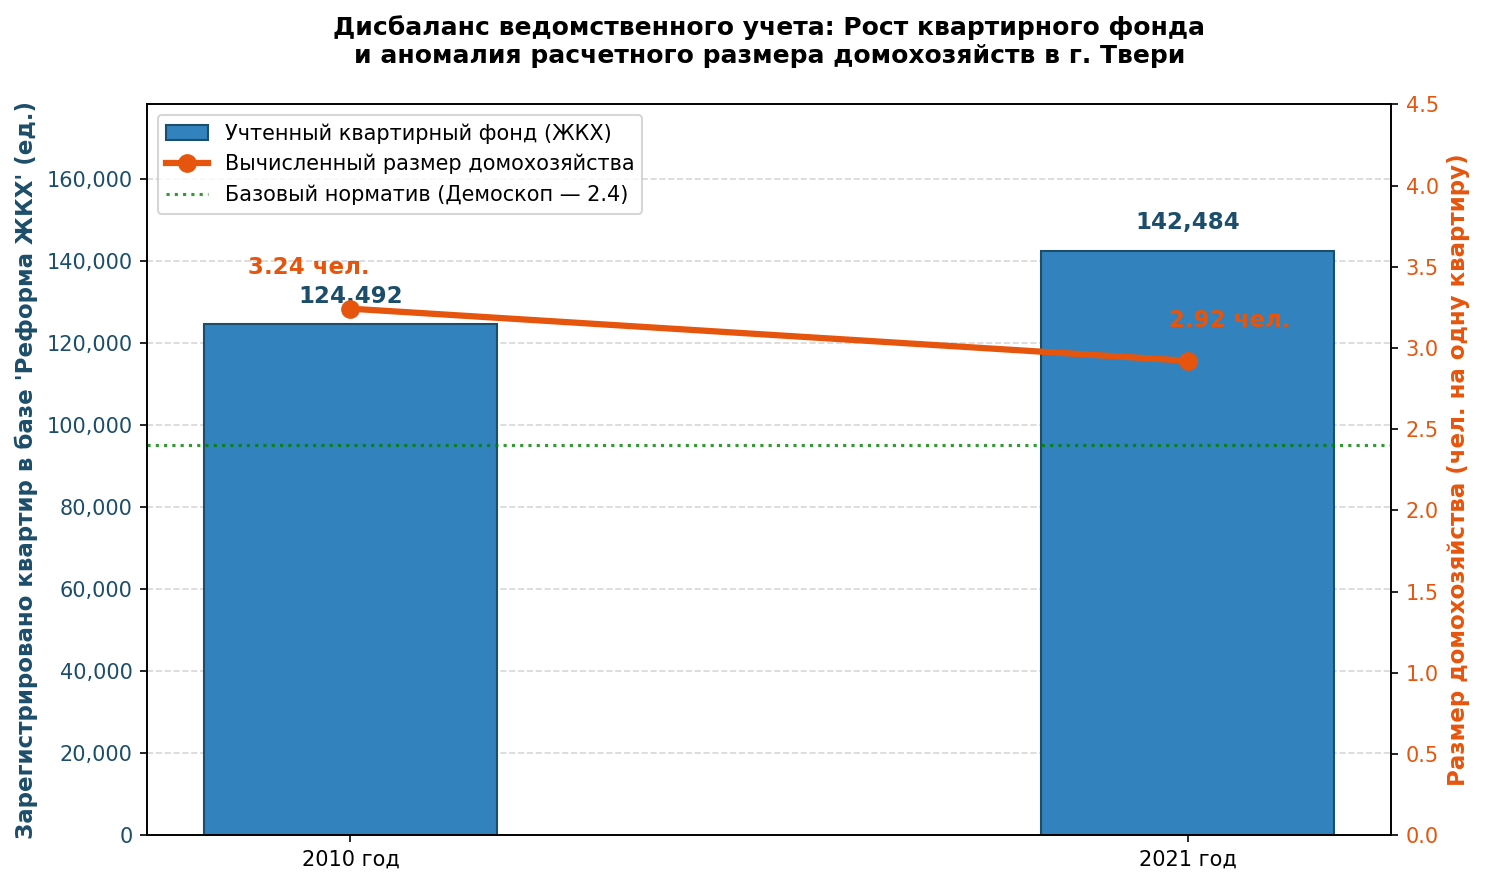

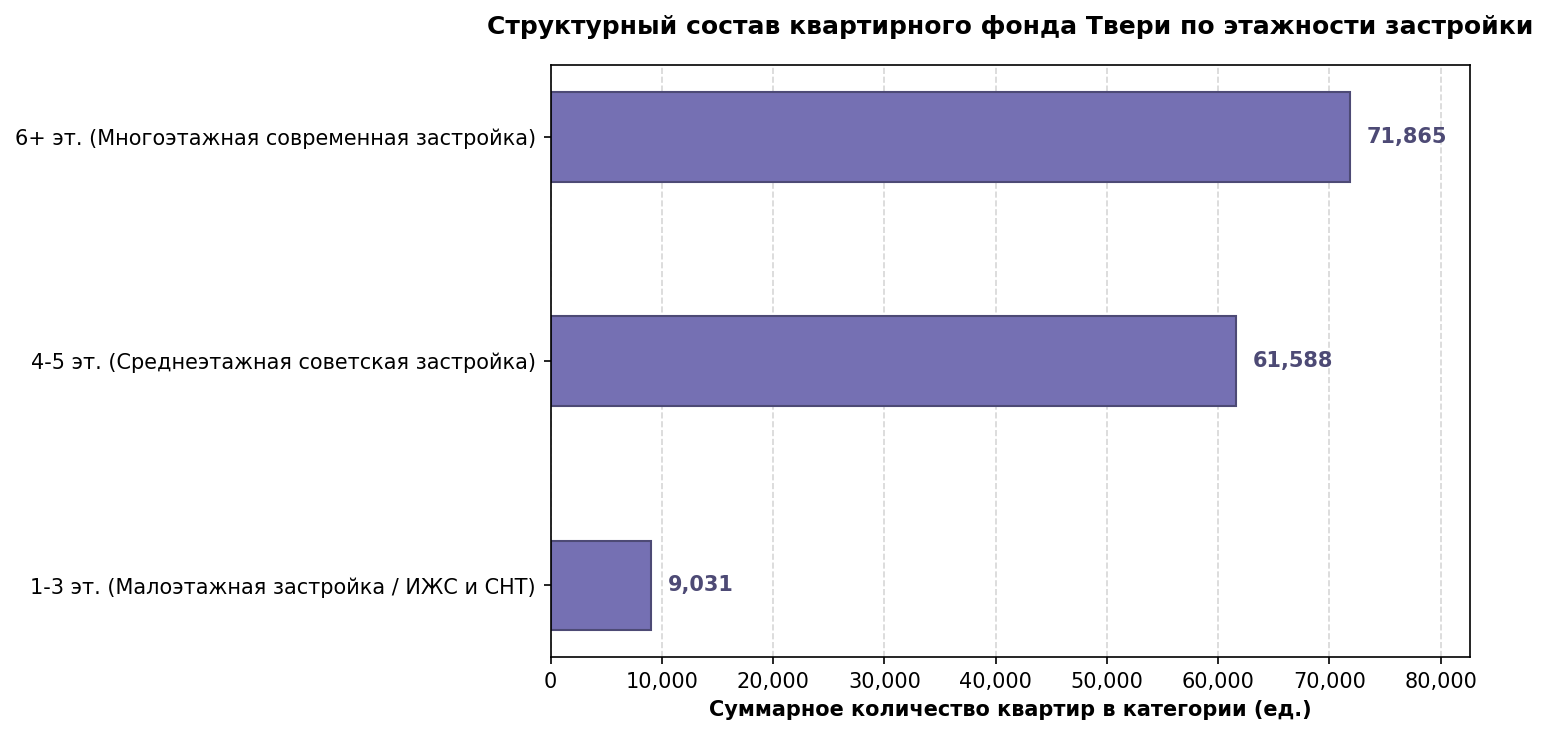

In [38]:
#Изначально специально для добавления графиков на диске была создана папка output, но для удобства в коде прописано ее автоматическое создание, если она не была создана ранее руками
os.makedirs("output", exist_ok=True)

# График №1
# Инициализируем первый рисунок (fig) и его главную левую ось (ax1)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Текстовые подписи для оси времени (годов)
years_labels = ["2010 год", "2021 год"]

# Собираем в список рассчитанные ранее объемы квартирного фонда для двух годов
apartment_volumes = [apartments_2010, apartments_2021]

# Собираем в список вычисленные коэффициенты размера домохозяйств
calculated_coefs = [hh_size_2010, hh_size_2021]

# Строим столбцы квартирного фонда на оси ax1, задаем ширину и границы
bars = ax1.bar(years_labels,apartment_volumes,color="#3182bd",width=0.35,edgecolor="#1c4e6b",label="Учтенный квартирный фонд (ЖКХ)",zorder=2,)

# Задаем название левой вертикальной оси и настраиваем ее шрифт
ax1.set_ylabel("Зарегистрировано квартир в базе 'Реформа ЖКХ' (ед.)",color="#1c4e6b",fontsize=11,fontweight="bold",)

# Окрашиваем числовые деления левой оси в синий цвет для визуального соответствия
ax1.tick_params(axis="y", labelcolor="#1c4e6b")

# Увеличиваем лимит левой оси вверх на 25% для удобства визуализации
ax1.set_ylim(0, max(apartment_volumes) * 1.25)

# Форматируем числа на левой оси: добавляем запятые как разделители тысяч
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ",")))

# Горизонтальная сетка
ax1.grid(axis="y", linestyle="--", alpha=0.5, zorder=1)

# Пробегаем циклом по каждому синему столбцу, чтобы написать точное число квартир сверху
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 4000, f"{int(yval):,}", ha="center", va="bottom", fontsize=11, fontweight="bold", color="#1c4e6b",)

# Создаем вторую вертикальную ось (ax2), которая разделяет ту же горизонтальную ось X
ax2 = ax1.twinx()

# Строим линейный график вычисленных коэффициентов
ax2.plot(years_labels,calculated_coefs,color="#e6550d",marker="o",linewidth=3,markersize=8,label="Вычисленный размер домохозяйства",zorder=3,)

# Задаем название правой вертикальной оси и настраиваем ее шрифт
ax2.set_ylabel("Размер домохозяйства (чел. на одну квартиру)",color="#e6550d",fontsize=11,fontweight="bold",)

# Окрашиваем числовые деления правой оси в оранжевый цвет
ax2.tick_params(axis="y", labelcolor="#e6550d")

# Проводим зеленую пунктирную линию на уровне 2.4 - базового значения для Тверской области
ax2.axhline(2.4,color="green",linestyle=":",alpha=0.8,linewidth=1.5,label="Базовый норматив (Демоскоп — 2.4)",)

# Задаем фиксированные рамки для правой оси от 0 до 4.5 человек
ax2.set_ylim(0, 4.5)

# Работа с подписями для удобства визуализации
for i, val in enumerate(calculated_coefs):
    # Для первой точки (2010) смещаем текст чуть выше и левее, для второй - выше и правее
    x_offset = -0.05 if i == 0 else 0.05
    ax2.text(i + x_offset,val + 0.18,f"{val:.2f} чел.",ha="center",va="bottom",fontsize=11,fontweight="bold",color="#e6550d",)

# Объединяем легенду от левой и правой оси
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper left", fontsize=10, frameon=True)

# Заголовок графика №1
plt.title("Дисбаланс ведомственного учета: Рост квартирного фонда\nи аномалия расчетного размера домохозяйств в г. Твери",fontsize=12,fontweight="bold",pad=20,)

fig.tight_layout()

# Сохраняем график №1 в файл PNG
plt.savefig("output/tver_household_dynamics.png", dpi=300)
plt.show()


# График №2
# Создаем новый рисунок, увеличивая высоту для удобства визуализации
fig, ax = plt.subplots(figsize=(10, 5))

# Строим столбцы
bars_h = ax.barh(morphology_summary["building_morphology"], morphology_summary["living_quarters_count"],color="#7570b3",edgecolor="#4d4a75",height=0.4,zorder=2,)

# Задаем заголовок и подписи осей
ax.set_title("Структурный состав квартирного фонда Твери по этажности застройки",fontsize=12,fontweight="bold",pad=15,)
ax.set_xlabel("Суммарное количество квартир в категории (ед.)", fontweight="bold")

# Настраиваем лимит по оси X, чтобы текстовые подписи значений влезли справа
ax.set_xlim(0, max(morphology_summary["living_quarters_count"]) * 1.15)

# Включаем сетку
ax.grid(axis="x", linestyle="--", alpha=0.5, zorder=1)

# Форматируем числа горизонтальной оси X, разделяя тысячи запятыми
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ",")))

# Пробегаем циклом по горизонтальным столбцам и подписываем точные значения справа от них
for bar in bars_h:
    xval = bar.get_width()
    ax.text(xval + 1500,bar.get_y() + bar.get_height() / 2,f"{int(xval):,}",ha="left",va="center",fontsize=10,fontweight="bold",color="#4d4a75",)

# Корректируем геометрию отступов второго рисунка
plt.tight_layout()

# Сохраняем график структуры этажности №2 в папку output
plt.savefig("output/tver_building_morphology.png", dpi=300)
plt.show()



## Выводы и анализ

Проведенный расчет выявил явные структурные аномалии ведомственного учета: вычисленный локальный размер домохозяйства для Твери составил **3.24 чел.** в 2010 году и **2.92 чел.** в 2021 году. Это существенно выше нормативной базы [Демоскоп Weekly](https://www.demoscope.ru/weekly/ssp/rus_hh_10.php) (2.4 чел.). Это расхождение в данных подтверждает гипотезу о *критическом скрытом недоучете жилой площади* в таблицах ведомств при отсутствии ГИС-корректировки.

### Анализ морфологии застройки и ключевые причины искажения:
Обратимся к построенному графику структуры фонда по высотности №2. Он наглядно демонстрирует, что доминирующий объем учтенных квартир Твери сосредоточен в среднеэтажной советской застройке (более 60 тыс.) и современной многоэтажной застройке от 6 этажей и выше (более 70 тыс. квартир). При этом доля малоэтажного сектора (1–3 этажа) в базе составляет менее 10 тыс. квартир. 
Это распределение подтверждает искажение данных:
1. **Игнорирование частного сектора (ИЖС):** Реестр «Реформы ЖКХ» агрегирует информацию преимущественно по *многоквартирному фонду*. Огромные по площади территории индивидуальной жилой застройки Твери, зафиксированные на графике этажности минимальным объемом, физически выпали из знаменателя формулы. Меньше учтенных квартир при неизменном населении города по [Росстату](https://rosstat.gov.ru) автоматически приводят к завышению коэффициента.
2. **Технические пустоты заполнения:** Как показала данная работа, значительный процент домов Твери содержит нулевые маркеры квартир из-за несвоевременного заполнения базы управляющими компаниями. На этапе предобработки эти данные отсекаются, искусственно занижая реальную емкость жилья и коэффициент соответственно.
3. **Фактор новостроек и атомизации:** Наблюдаемый тренд падения коэффициента с 3.24 до 2.92 отражает постепенное улучшение учета домов ведомствами к 2021 году.

### Транспортные последствия для Твери:
Опираться на некорректированные ведомственные базы данных в транспортном проектировании опасно. Из-за скрытых данных в учете ЖКХ, целые районы частного сектора и недоучтенные жилые дома маскируют реальные очаги концентрации пассажиропотоков. После полной ликвидации трамвайной (2018 г.) и троллейбусной (2020 г.) систем Твери эти недоучтенные зоны формируют зоны перегрузки коммерческих автобусных маршрутов и провоцируют хаотичную автомобилизацию города.
